Chart saved to: ../results\models_comparison_chart.png


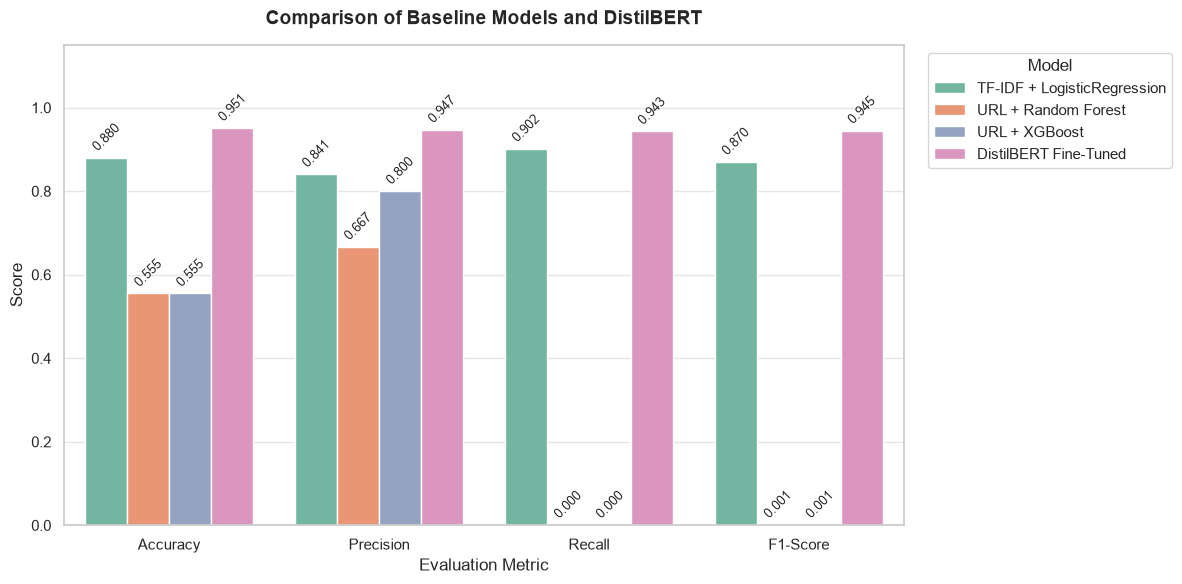

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot styles
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)

RESULTS_DIR = "../results"

# 1. Load metrics from files
baseline_path = os.path.join(RESULTS_DIR, "baseline_metrics.csv")
bert_path = os.path.join(RESULTS_DIR, "distilbert_metrics.csv")

df_list = []
if os.path.exists(baseline_path):
    df_list.append(pd.read_csv(baseline_path))
if os.path.exists(bert_path):
    df_list.append(pd.read_csv(bert_path))

if df_list:
    df_all = pd.concat(df_list, ignore_index=True)

    # Save the combined metrics table
    all_metrics_path = os.path.join(RESULTS_DIR, "all_models_metrics.csv")
    df_all.to_csv(all_metrics_path, index=False)

    # 2. Reshape data for plotting (Melt)
    df_melted = df_all.melt(
        id_vars=["model"],
        value_vars=["accuracy", "precision", "recall", "f1"],
        var_name="Metric",
        value_name="Score"
    )

    metric_names = {
        "accuracy": "Accuracy",
        "precision": "Precision",
        "recall": "Recall",
        "f1": "F1-Score"
    }
    df_melted["Metric"] = df_melted["Metric"].map(metric_names)

    # 3. Build the chart
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.barplot(data=df_melted, x="Metric", y="Score", hue="model", palette="Set2", ax=ax)

    ax.set_title("Comparison of Baseline Models and DistilBERT", fontsize=14, fontweight="bold", pad=15)
    ax.set_ylim(0, 1.15)
    ax.set_ylabel("Score", fontsize=12)
    ax.set_xlabel("Evaluation Metric", fontsize=12)
    ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc='upper left')

    # Add numeric labels above the bars
    for p in ax.patches:
        height = p.get_height()
        if not pd.isna(height) and height > 0:
            ax.annotate(f'{height:.3f}',
                        (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='bottom',
                        fontsize=9, xytext=(0, 3),
                        textcoords='offset points', rotation=45)

    plt.tight_layout()

    # Save chart image to PNG
    chart_path = os.path.join(RESULTS_DIR, "models_comparison_chart.png")
    plt.savefig(chart_path, dpi=300, bbox_inches="tight")
    print(f"Chart saved to: {chart_path}")

    plt.show()
else:
    print("Metrics files not found in the results/ folder.")

In [4]:
# Display summary table of results
if 'df_all' in locals():
    # Format numbers to 4 decimal places
    styled_table = df_all.style.format({
        "accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}"
    }).hide(axis="index").set_caption("Model Evaluation Summary")

    display(styled_table)

model,accuracy,precision,recall,f1
TF-IDF + LogisticRegression,0.8802,0.8408,0.9016,0.8701
URL + Random Forest,0.5550,0.6667,0.0005,0.0009
URL + XGBoost,0.5550,0.8000,0.0005,0.0009
DistilBERT Fine-Tuned,0.9511,0.9470,0.9430,0.9450
